In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Flatten, Dense
print("done")

C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


done


In [ ]:
#import

#load data
#separate data
#normalize data

#define FNN (layers, input shape, activation func, = on all lines)
#compile (olm)
#train (X_train, y_train, epochs, batch_size, validation_split)

#evaluate
#plot

In [3]:
#load dataset
train_data = pd.read_csv('fashion-mnist_train.csv')
test_data = pd.read_csv('fashion-mnist_test.csv')

print(train_data.head())

   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0         0         0         

In [5]:
#features and labels
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [7]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [26]:
count = train_data.iloc[:, 0].nunique()
print("Unique: ", count)

Unique:  10


In [12]:
#define FNN
#layers, input shape, activation func
model = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')  #will return probabilities summing to 1, whichevr probability is highest, will be the label
])

In [15]:
#compile
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("done")

done


In [19]:
#train
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8810 - loss: 0.3336 - val_accuracy: 0.8617 - val_loss: 0.3853
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8827 - loss: 0.3267 - val_accuracy: 0.8667 - val_loss: 0.3747
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8861 - loss: 0.3191 - val_accuracy: 0.8680 - val_loss: 0.3776
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8859 - loss: 0.3146 - val_accuracy: 0.8707 - val_loss: 0.3597
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8897 - loss: 0.3085 - val_accuracy: 0.8693 - val_loss: 0.3592
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8907 - loss: 0.3034 - val_accuracy: 0.8772 - val_loss: 0.3469
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8920 - loss: 0.2992 - val_accuracy: 0.8725 - val_loss: 0.3551
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8941 - loss: 0.293

In [21]:
#evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test loss: ", test_loss)
print("Test accuracy: ", test_accuracy*100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8839 - loss: 0.3154
Test loss:  0.3154066205024719
Test accuracy:  88.3899986743927 %


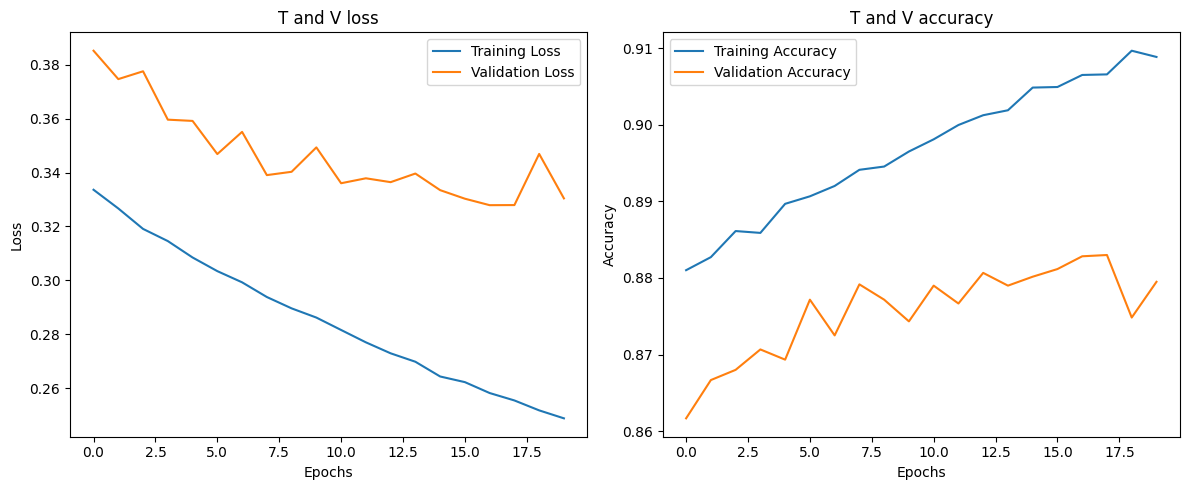

In [23]:
#plotting
plt.figure(figsize=(12, 5))

#Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label = "Training Loss")
plt.plot(history.history['val_loss'], label = "Validation Loss")
plt.title("T and V loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

#Loss
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = "Training Accuracy")
plt.plot(history.history['val_accuracy'], label = "Validation Accuracy")
plt.title("T and V accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()